<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 1 · Framing a forecast</p><p class="mh-facts"><span class="lvl lvl-introductory">Introductory</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Leakage is any information in the training data or features that would not be available when the forecast is actually made. It takes three forms: target leakage, where a feature is partly built from the value being predicted; temporal leakage, where a window, a fill or a fitted transform reaches past the forecast origin; and revision leakage, where training uses final values of inputs that were only provisional when the forecast was issued. All three break one rule: every feature on every row must be computable as of the origin. Ordinary backtests miss leaks, because the test rows are built by the same code as the training rows. On a synthetic weekly series, a centred 4-week mean cuts a ridge regression's backtest error from $3.12$ to $2.12$ tonnes, while the same model, fed what is actually known at issue time, misses by $4.98$ tonnes, worse than repeating last week. Afterwards you should be able to classify a leak, test any feature by hiding the future and recomputing it, keep fitted transforms inside a scikit-learn `Pipeline`, and join revised inputs as of the issue date.
:::


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from feature_engine.timeseries.forecasting import WindowFeatures
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110

## What counts as leakage

Leakage is information in the training data or the features that would not be available when the forecast is actually made. Kaufman and colleagues define it, for data mining in general, as information about the target that should not legitimately be available to learn from, and argue that it is avoided mainly by how data are stored and by keeping what a model learns from separate from what it predicts on[^1].

For a forecast $\hat{y}_{t+h \mid t}$, as written in [Horizon, frequency and target](../horizon-frequency-and-target.qmd), "legitimately available" has a date attached:

> **The as-of rule.** For every row, every feature must be computable from the data as they stood at the forecast origin $t$: the values that had arrived by then, in the versions that existed then.

Leaks break the rule in three ways:

| Kind | What leaks in | Forecasting example | Fix |
|---|---|---|---|
| **Target** | the value being predicted | a season total used to predict one week of that season; a 4-week mean that ends on the target week | build from lags of the target only |
| **Temporal** | rows from after the origin | a centred rolling window; gaps filled with `bfill`; a scaler, imputer or encoder fitted on the whole series before the split | trailing windows; forward fills; fit transforms on training rows only |
| **Revision** | later versions of an input | final, reconciled intake volumes where only a provisional figure existed at issue time | keep every published version with its date; join as of the origin |

The kinds overlap, and the label matters less than the question: *at the moment this forecast is issued, could this number be computed?* An ordinary backtest will not ask it for you. The test rows are built by the same code as the training rows, so the leak is in both and the score goes up.

## A leak that passes the backtest

The data are synthetic: six years of weekly volume received at a packhouse, generated with a fixed seed as

$$y_t = 40 + 25 \max\!\left(0,\ \sin\frac{2\pi (w_t - 13)}{52}\right) + \varepsilon_t, \qquad \varepsilon_t = 0.6\,\varepsilon_{t-1} + \eta_t$$

where $y_t$ is the volume in week $t$ in tonnes, $w_t$ is the week of the year ($0$ to $51$), $\varepsilon_t$ is noise in tonnes that carries $60\%$ of itself into the next week, and $\eta_t$ are independent normal shocks with standard deviation $4\text{ t}$. That is a floor of $40\text{ t}$ a week with a peak season between weeks $13$ and $39$.

In [2]:
rng = np.random.default_rng(42)
n = 6 * 52
weeks = pd.date_range("2020-01-04", periods=n, freq="W-SAT")
week_of_year = np.arange(n) % 52

eps = np.zeros(n)
for t in range(1, n):
    eps[t] = 0.6 * eps[t - 1] + rng.normal(0, 4)
season = 40 + 25 * np.sin(2 * np.pi * (week_of_year - 13) / 52).clip(0)
y = pd.Series(season + eps, index=weeks, name="tonnes")
print(f"{n} weeks, {weeks[0]:%Y-%m-%d} to {weeks[-1]:%Y-%m-%d}; {y.min():.1f} to {y.max():.1f} t per week")

312 weeks, 2020-01-04 to 2025-12-20; 28.7 to 72.5 t per week


The forecast is one week ahead, $h = 1$, with no data latency. The sixth year is held out; the first five train the model, the first of them only as history for a 52-week lag. Each row gets last week's volume, the volume $52$ weeks earlier, the week of the year as a sine–cosine pair, and a 4-week mean of volume computed one of two ways:

- **trailing**: weeks $t-4$ to $t-1$, all known at the origin;
- **centred**: weeks $t-2$ to $t+1$, which contains the target week and the week after it. It is what `rolling(4, center=True)` returns, a natural smoothing step while exploring data.

In [3]:
base = pd.DataFrame(
    {
        "lag_1": y.shift(1),
        "lag_52": y.shift(52),
        "week_sin": np.sin(2 * np.pi * week_of_year / 52),
        "week_cos": np.cos(2 * np.pi * week_of_year / 52),
    },
    index=weeks,
)
trailing = y.shift(1).rolling(4).mean()  # weeks t-4 .. t-1
centred = y.rolling(4, center=True).mean()  # weeks t-2 .. t+1
honest = base.assign(mean_4=trailing)
leaky = base.assign(mean_4=centred)

rows = honest.dropna().index.intersection(leaky.dropna().index)
train, test = rows[rows < weeks[-52]], rows[rows >= weeks[-52]]
print(f"train {len(train)} weeks, test {len(test)} weeks; dropped from the end: {weeks.difference(rows)[-1]:%Y-%m-%d}")

train 208 weeks, test 51 weeks; dropped from the end: 2025-12-20


The final week drops out because its centred window needs a week that has not happened yet: a feature that cannot be computed for the newest row is a leak announcing itself.

The same model, ridge regression, is trained on each feature set and scored on the held-out year by mean absolute error (MAE), with persistence (this week equals last week) as the reference.

In [4]:
def test_mae(pred):
    return mean_absolute_error(y[test], pred)


m_honest = Ridge().fit(honest.loc[train], y[train])
m_leaky = Ridge().fit(leaky.loc[train], y[train])

scores = pd.Series(
    {
        "persistence (last week's volume)": test_mae(y.shift(1)[test]),
        "honest: trailing mean": test_mae(m_honest.predict(honest.loc[test])),
        "leaky: centred mean, as backtested": test_mae(m_leaky.predict(leaky.loc[test])),
        "leaky: centred mean, as deployed": test_mae(m_leaky.predict(honest.loc[test])),
    },
    name="test MAE (t)",
)
scores.round(2)

persistence (last week's volume)      3.41
honest: trailing mean                 3.12
leaky: centred mean, as backtested    2.12
leaky: centred mean, as deployed      4.98
Name: test MAE (t), dtype: float64

The honest model improves on persistence by $1 - 3.12/3.41 = 9\%$. The leaky model reports an error $1 - 2.12/3.41 = 38\%$ lower than persistence, and that figure can never be reproduced. At issue time weeks $t$ and $t+1$ have not happened, so the centred mean cannot be computed; the nearest thing that can is the trailing mean. Fed that, the leaky model misses by $4.98\text{ t}$, worse than persistence, because it learned to lean on a column that, in training, contained the answer.

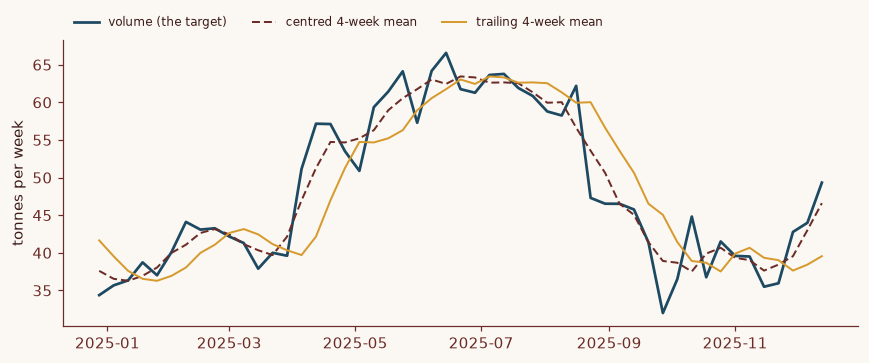

In [5]:
c_obs, c_trail, c_centre, _ = fallcolor.palette.discrete("default")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(test, y[test], color=c_obs, lw=1.8, label="volume (the target)")
ax.plot(test, centred[test], color=c_centre, lw=1.3, ls=(0, (4, 2)), label="centred 4-week mean")
ax.plot(test, trailing[test], color=c_trail, lw=1.3, label="trailing 4-week mean")
ax.set_ylabel("tonnes per week")
ax.legend(fontsize=8, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
plt.show()

<strong>Figure 1 | The centred mean tracks the target because it is partly made of it.</strong> The held-out year of the synthetic series. The centred mean (dashed) turns with the target; the trailing mean, the only one computable at the origin, turns after it.

### How to catch it

**Too good to be true.** A large gain over a naive baseline from one new feature, like the $38\%$ above, needs an explanation before it gets a celebration.

**One feature dominates.** Permutation importance shuffles one column of the test rows at a time and records how much the error grows:

In [6]:
importance = pd.DataFrame(
    {
        name: permutation_importance(
            model, X.loc[test], y[test], scoring="neg_mean_absolute_error", n_repeats=20, random_state=0
        ).importances_mean
        for name, model, X in [("honest", m_honest, honest), ("leaky", m_leaky, leaky)]
    },
    index=honest.columns,
)
importance.round(2)  # increase in test MAE (t) when the column is shuffled

,honest,leaky
lag_1,6.45,2.05
lag_52,0.31,-0.02
week_sin,0.04,0.05
week_cos,1.28,0.22
mean_4,0.55,13.73


The honest model leans on last week's volume ($6.45\text{ t}$). The leaky one leans on the centred mean ($13.73\text{ t}$), which displaces last week's volume to $2.05\text{ t}$. Dominance is a symptom, not a proof: legitimate features dominate too.

**Hide the future and recompute.** The as-of rule can be tested directly, without a model. For each target week, blank out that week and everything after it, recompute the feature, and check it has not changed:

In [7]:
def known_at_origin(make_feature, y, targets):
    """True if each target week's feature is unchanged when that week and all later weeks are hidden."""
    full = make_feature(y)
    return all(np.isclose(make_feature(y.where(y.index < t))[t], full[t]) for t in targets)


candidates = {
    "centred 4-week mean": lambda s: s.rolling(4, center=True).mean(),
    "4-week mean ending on the target week": lambda s: s.rolling(4).mean(),
    "lag 1, standardised on the whole series": lambda s: ((s - s.mean()) / s.std()).shift(1),
    "trailing 4-week mean": lambda s: s.shift(1).rolling(4).mean(),
    "feature_engine WindowFeatures": lambda s: WindowFeatures(
        window=4, functions="mean", missing_values="ignore"
    ).fit_transform(s.to_frame("y"))["y_window_4_mean"],
}
pd.Series({name: known_at_origin(f, y, test) for name, f in candidates.items()}, name="known at origin")

centred 4-week mean                        False
4-week mean ending on the target week      False
lag 1, standardised on the whole series    False
trailing 4-week mean                        True
feature_engine WindowFeatures               True
Name: known at origin, dtype: bool

The three leaks fail. The standardised lag fails through its mean and standard deviation, which include the held-out year: the "scaler fitted before the split" from the table, caught without fitting a model. `WindowFeatures`, which [Feature engineering with feature_engine](../forecast/1_feature_engineering.ipynb) uses for its rolling means, passes because by default it shifts the window back one row (`periods=1`). The test is cheap enough to run on every feature, and it catches leaks that do not move the score.

## Fit transforms inside the training window

Any step that learns from data, such as a scaler's mean, an imputer's fill value or an encoder's lookup table, is a small model, and the as-of rule applies to it. Some such leaks do no measurable harm: standardising features changes no prediction of an ordinary least-squares regression or a decision tree, and the `OrdinalEncoder` in the feature engineering module, fitted on every row, learns only category names. The harmful kind learns from the target.

A common example in agriculture is a seasonal profile: replace the week of the year with the average volume in that week across the years on record. As a scikit-learn transformer, the averaging happens in `fit`:

In [8]:
class WeekProfile(TransformerMixin, BaseEstimator):
    """Replace week of year with the mean target for that week, learned in fit."""

    def fit(self, X, y):
        self.profile_ = pd.Series(y, index=X.index).groupby(X["week"]).mean()
        return self

    def transform(self, X):
        return X.assign(week=X["week"].map(self.profile_))


X2 = honest.drop(columns=["week_sin", "week_cos"]).assign(week=week_of_year)

Fitted once on all six years, each held-out week's profile contains that week's own volume. Inside a `Pipeline`, `fit` sees only the training rows and `predict` reuses what was stored. A third version builds the profile as of each row, from previous years only, which makes it a stateless feature like a lag:

In [9]:
profile_all = WeekProfile().fit(X2, y)  # all six years, test year included
m_all = Ridge().fit(profile_all.transform(X2.loc[train]), y[train])

pipe = make_pipeline(WeekProfile(), Ridge()).fit(X2.loc[train], y[train])

past_years = y.groupby(week_of_year).transform(lambda s: s.shift(1).expanding().mean())
as_of = X2.assign(week=past_years)
m_as_of = Ridge().fit(as_of.loc[train], y[train])

pd.DataFrame(
    {
        "test MAE (t)": [
            test_mae(m_all.predict(profile_all.transform(X2.loc[test]))),
            test_mae(pipe.predict(X2.loc[test])),
            test_mae(m_as_of.predict(as_of.loc[test])),
        ],
        "weight on profile": [m_all.coef_[-1], pipe[-1].coef_[-1], m_as_of.coef_[-1]],
    },
    index=["fitted on all six years", "fitted in a Pipeline", "as of each row"],
).round(2)

,test MAE (t),weight on profile
fitted on all six years,3.17,0.76
fitted in a Pipeline,3.69,0.83
as of each row,3.26,0.44


The leaky fit scores $3.17\text{ t}$, the `Pipeline` $3.69\text{ t}$: the difference is the held-out weeks' own volumes inside their features, the leak a `Pipeline` exists to stop.

The pipeline's number is honest but not the best this feature can do. In the training years each row's profile still contains its own volume, one value in four, so the profile looks more informative in training than it will be on new data, and the model gives it a weight of $0.83$. Built as of each row, it gets $0.44$ and scores $3.26\text{ t}$. Target leakage confined to the training rows does not flatter the test score; here it degrades the model, though with other random seeds the gap between the last two rows is smaller and occasionally reversed. A `Pipeline` keeps the test rows out of `fit`, but target-derived features still have to be built as of each row, like lags. (None of the three beats the sine–cosine model of the previous section, $3.12\text{ t}$; the point is the gaps between them.)

The working habit: put every fitted step, whether scaler, imputer, encoder or feature selector, inside the pipeline, and refit the whole pipeline at every backtest origin.

## Revisions and the as-of join

Some inputs change after they are first published: intake reported provisionally and reconciled weeks later, or official statistics released as preliminary estimates and then revised. A table that keeps only the latest value replaces what was known with what was learned later, and a model trained on it is fitted to cleaner inputs than it will ever receive.

The fix is in storage: keep every published version of a value, a *vintage*, with its publication date, and join features as of each issue date. `pd.merge_asof` does this, taking for each row on the left the latest row on the right whose date is not after it. The vintages below are synthetic, for a forecast issued each Monday that needs the week ending two days earlier:

In [10]:
vintages = pd.DataFrame(
    {
        "week": pd.to_datetime(["2025-06-07", "2025-06-07", "2025-06-14", "2025-06-14", "2025-06-21"]),
        "published": pd.to_datetime(["2025-06-09", "2025-06-23", "2025-06-16", "2025-06-30", "2025-06-23"]),
        "tonnes": [41.0, 46.5, 52.0, 55.8, 49.0],
    }
).sort_values("published")
issues = pd.DataFrame(
    {
        "issued": pd.to_datetime(["2025-06-09", "2025-06-16", "2025-06-23", "2025-06-30"]),
        "week": pd.to_datetime(["2025-06-07", "2025-06-14", "2025-06-21", "2025-06-28"]),
    }
)
known = pd.merge_asof(issues, vintages, left_on="issued", right_on="published", by="week")
known.assign(final=known["week"].map(vintages.groupby("week")["tonnes"].last()))

,issued,week,published,tonnes,final
0,2025-06-09,2025-06-07,2025-06-09,41.0,46.5
1,2025-06-16,2025-06-14,2025-06-16,52.0,55.8
2,2025-06-23,2025-06-21,2025-06-23,49.0,49.0
3,2025-06-30,2025-06-28,NaT,NaN,NaN


On 9 June the forecast would have seen $41.0\text{ t}$ for the week ending 7 June; the table now says $46.5\text{ t}$, and a backtest that joins on the week alone uses the later figure. On 30 June the week ending 28 June has not been published at all. That is the data latency $d$ from the previous module appearing as a missing value; fall back to an older week or leave it missing, never fill it with a value published later.

These checks make the features honest. Whether the evaluation that scores them is honest, with how many origins, against which baselines and with the model refitted at each, is the subject of [Backtesting properly](../backtesting/backtesting_properly.ipynb).

## Key takeaways

- Leakage is information in the training data or features that would not be available when the forecast is issued. Ask of every feature: could it be computed at the origin, from the data as they stood then?
- Target, temporal and revision leaks, such as a centred window, a scaler fitted on the whole series or a final revised figure, all fail that test.
- A backtest does not catch leakage, because the test rows are built by the same code. Here a centred mean cut the backtest error from $3.12$ to $2.12\text{ t}$ and raised the error in operation to $4.98\text{ t}$.
- Treat a large gain over a naive baseline, or one dominant feature, as a warning; confirm by hiding the future, recomputing the feature and checking it has not changed.
- Fit every learned transform inside a scikit-learn `Pipeline`, build target-derived features as of each row, and store every version of a revised input so it can be joined with `merge_asof`.

## References

[^1]: Kaufman, S., Rosset, S., Perlich, C. & Stitelman, O. Leakage in data mining: formulation, detection, and avoidance. *ACM Trans. Knowl. Discov. Data* **6**, 1–21 (2012). https://doi.org/10.1145/2382577.2382579


<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/horizon-frequency-and-target.html"><span>Previous</span>Horizon, frequency and target</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/backtesting/backtesting_properly.html"><span>Next</span>Backtesting properly</a></div>
<!-- CURRICULUM_FOOTER_END -->